#  Breast Cancer Classification — Machine Learning Project

**Objective.** Build a reproducible pipeline to distinguish **malignant** from **benign** tumors using numerical measurements, compare several models, select a model without data leakage, and analyze its errors.

> **Important limitation:** This is an educational project using the public *Breast Cancer Wisconsin* dataset included in scikit-learn. The model is neither a medical device nor a real diagnostic tool. Performance on this dataset does not guarantee generalization to other hospitals or populations.

1. Understand the problem and audit the data
2. Exploratory data analysis (quality, distributions, correlations)
3. Split training and test data before any fitting
4. Integrate preprocessing into pipelines
5. Compare models using stratified cross-validation
6. Tune hyperparameters using the training set only
7. Perform a single final evaluation on the test set
8. Interpretability, limitations, and deployment considerations

## 0. Configuration and Reproducibility

Plots use a consistent layout. The random seed is fixed to make results easier to reproduce.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay,
    PrecisionRecallDisplay, make_scorer
)
from sklearn.inspection import permutation_importance
from sklearn.calibration import CalibrationDisplay
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score

SEED = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.precision", 3)

print("Environment ready.")

Environment ready.


## 1. Loading and Understanding the Data

The dataset contains 569 observations and 30 numerical features. The scikit-learn target is encoded as `0 = malignant` and `1 = benign`. For metrics focused on cancer detection, we explicitly define the positive class as **malignant** to avoid ambiguity.

In [2]:
dataset = load_breast_cancer(as_frame=True)
X = dataset.data.copy()
y_original = dataset.target.copy()

# Explicit target: 1 = malignant, 0 = benign
y = (y_original == 0).astype(int).rename("malignant")

print(f"Observations: {X.shape[0]:,}")
print(f"Features: {X.shape[1]}")
print(f"Memory usage: {X.memory_usage(deep=True).sum() / 1024:.1f} KB")
display(pd.DataFrame({
    "Item": ["Observations", "Features", "Missing values", "Duplicate rows"],
    "Value": [len(X), X.shape[1], int(X.isna().sum().sum()), int(X.duplicated().sum())]
}))

Observations: 569
Features: 30
Memory usage: 133.5 KB


,Item,Value
0,Observations,569
1,Features,30
2,Missing values,0
3,Duplicate rows,0


In [3]:
# Feature dictionary and preview
display(X.head())
display(X.describe().T.rename_axis("Feature"))

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.118,0.278,0.300,0.147,0.242,0.079,1.095,0.905,8.589,153.40,0.006,0.049,0.054,0.016,0.030,0.006,25.38,17.33,184.60,2019.0,0.162,0.666,0.712,0.265,0.460,0.119
1,20.57,17.77,132.90,1326.0,0.085,0.079,0.087,0.070,0.181,0.057,0.543,0.734,3.398,74.08,0.005,0.013,0.019,0.013,0.014,0.004,24.99,23.41,158.80,1956.0,0.124,0.187,0.242,0.186,0.275,0.089
2,19.69,21.25,130.00,1203.0,0.110,0.160,0.197,0.128,0.207,0.060,0.746,0.787,4.585,94.03,0.006,0.040,0.038,0.021,0.022,0.005,23.57,25.53,152.50,1709.0,0.144,0.424,0.450,0.243,0.361,0.088
3,11.42,20.38,77.58,386.1,0.142,0.284,0.241,0.105,0.260,0.097,0.496,1.156,3.445,27.23,0.009,0.075,0.057,0.019,0.060,0.009,14.91,26.50,98.87,567.7,0.210,0.866,0.687,0.258,0.664,0.173
4,20.29,14.34,135.10,1297.0,0.100,0.133,0.198,0.104,0.181,0.059,0.757,0.781,5.438,94.44,0.011,0.025,0.057,0.019,0.018,0.005,22.54,16.67,152.20,1575.0,0.137,0.205,0.400,0.163,0.236,0.077


,count,mean,std,min,25%,50%,75%,max
Feature,,,,,,,,
mean radius,569.0,14.127,3.524,6.981e+00,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710e+00,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,4.379e+01,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,1.435e+02,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,5.263e-02,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,1.938e-02,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000e+00,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000e+00,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,1.060e-01,0.162,0.179,0.196,0.304


### 1.1 Target Distribution

Class imbalance can make accuracy misleading. We examine the absolute and relative frequency of each class before selecting evaluation metrics.

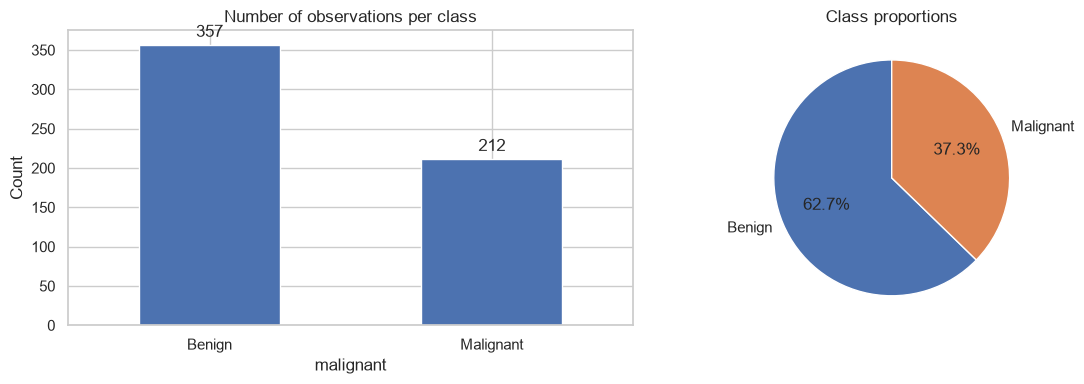

In [4]:
target_counts = y.map({1: "Malignant", 0: "Benign"}).value_counts().reindex(["Benign", "Malignant"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
target_counts.plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("Number of observations per class")
axes[0].set_ylabel("Count")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height())}", (p.get_x()+p.get_width()/2, p.get_height()),
                     ha="center", va="bottom", xytext=(0, 3), textcoords="offset points")
axes[1].pie(target_counts.values, labels=target_counts.index, autopct="%1.1f%%", startangle=90)
axes[1].set_title("Class proportions")
plt.tight_layout()
plt.show()

## 2. Data Quality Audit and Exploratory Analysis

The checks cover missing values, duplicates, constant features, and distributions. Outliers are not removed automatically: in a biomedical context, they may contain meaningful signal.

In [5]:
missing = X.isna().sum().sort_values(ascending=False)
quality = pd.DataFrame({
    "Data type": X.dtypes.astype(str),
    "Missing values": X.isna().sum(),
    "% missing": (X.isna().mean()*100),
    "Unique values": X.nunique(),
    "Standard deviation": X.std()
})
display(quality.sort_values(["Missing values", "Unique values"], ascending=[False, True]).head(12))
print("Number of constant columns:", int((X.nunique() <= 1).sum()))
print("Number of fully duplicated rows:", int(X.duplicated().sum()))

,Data type,Missing values,% missing,Unique values,Standard deviation
worst smoothness,float64,0,0.0,411,0.023
mean symmetry,float64,0,0.0,432,0.027
mean radius,float64,0,0.0,456,3.524
worst radius,float64,0,0.0,457,4.833
mean smoothness,float64,0,0.0,474,0.014
mean texture,float64,0,0.0,479,4.301
worst concave points,float64,0,0.0,492,0.066
symmetry error,float64,0,0.0,498,0.008
mean fractal dimension,float64,0,0.0,499,0.007
worst symmetry,float64,0,0.0,500,0.062


Number of constant columns: 0
Number of fully duplicated rows: 0


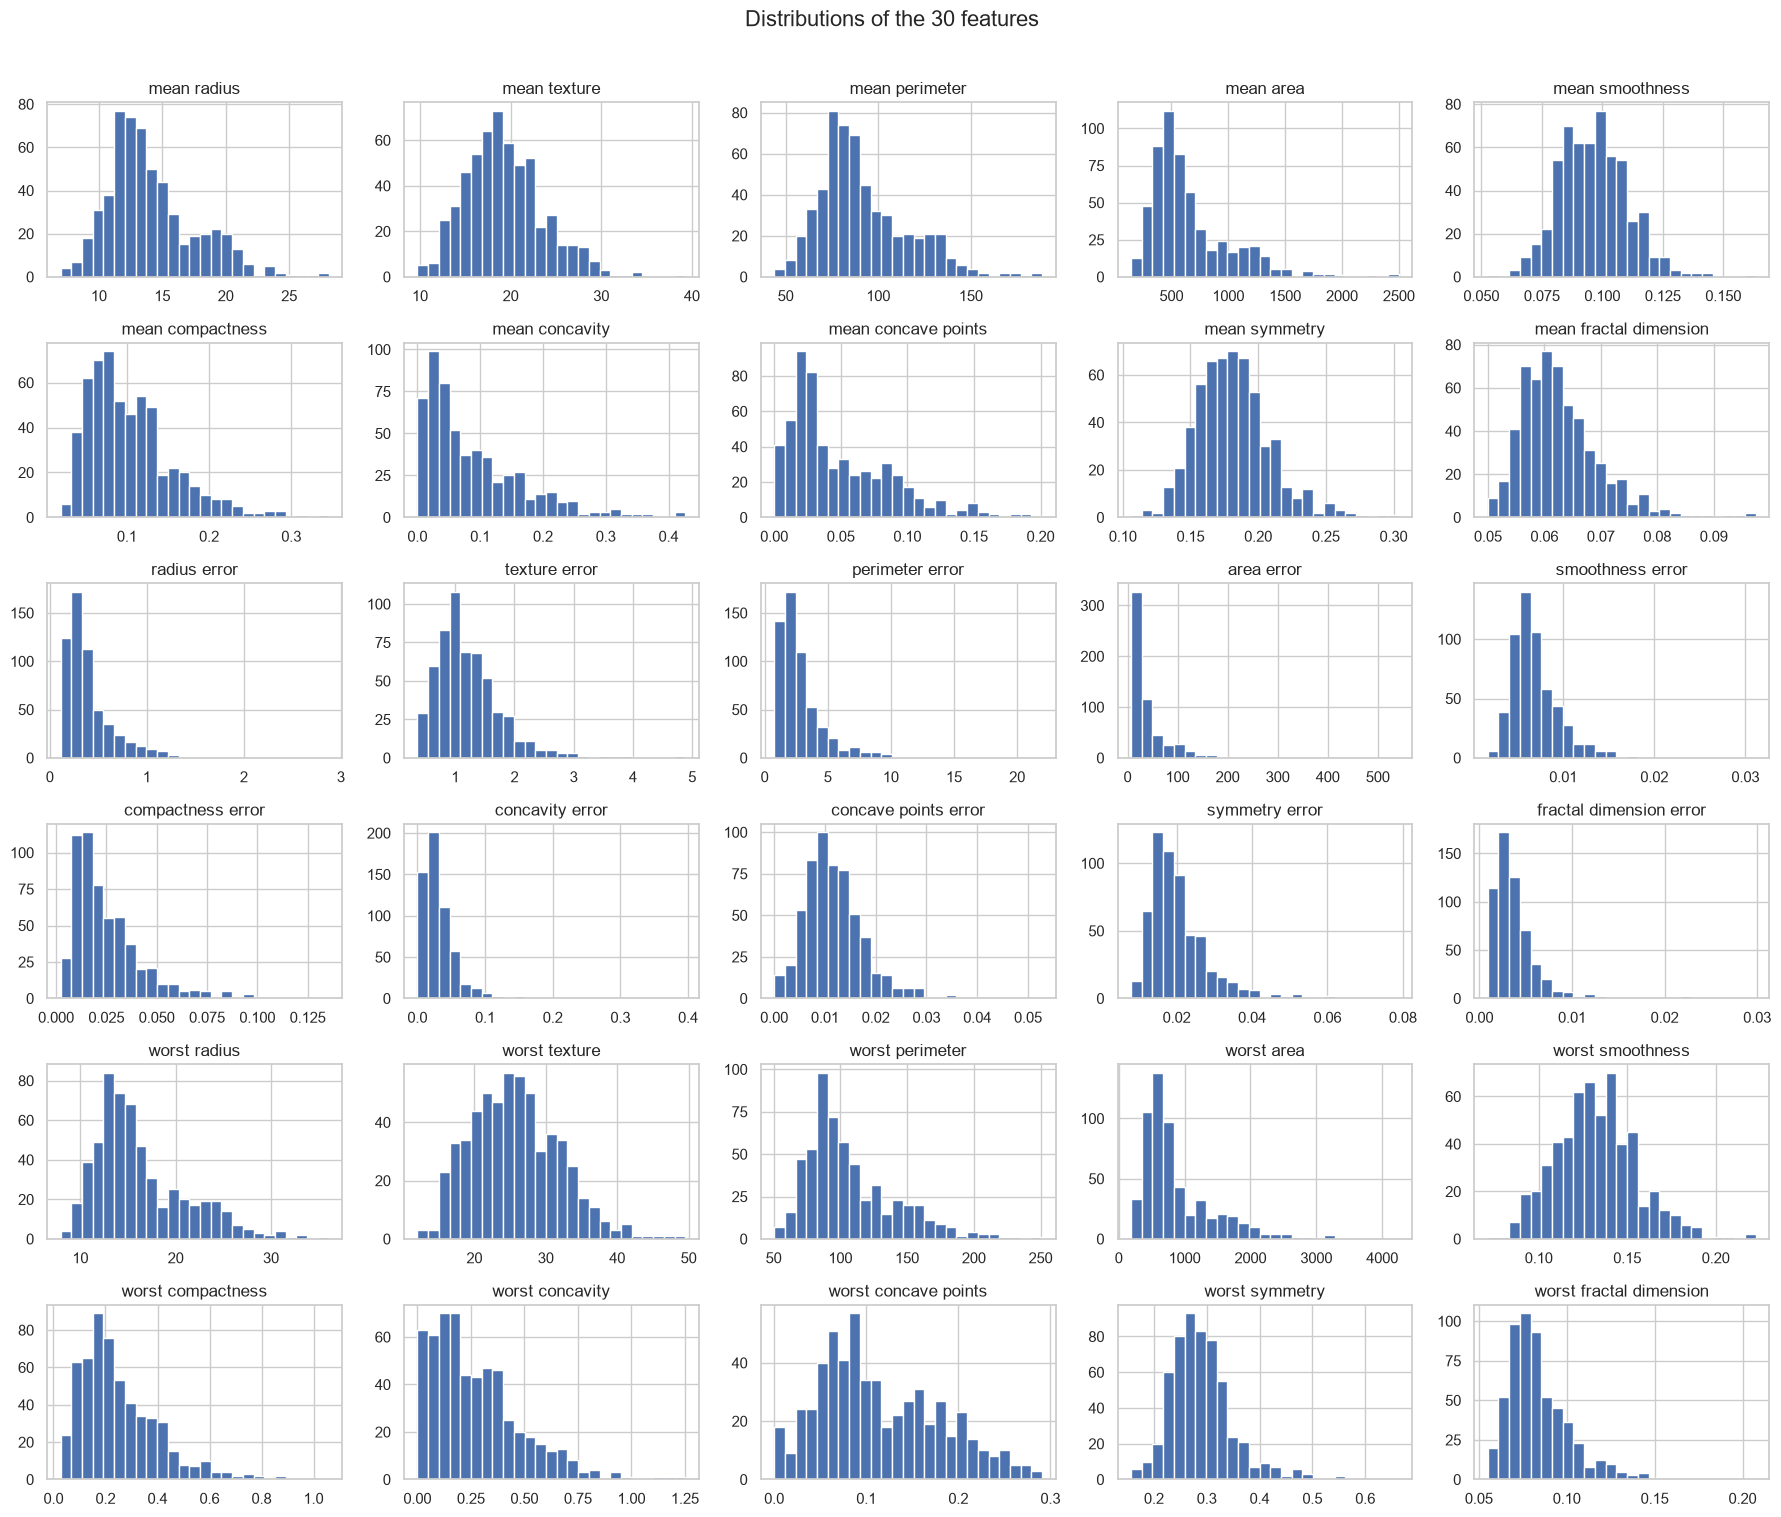

In [6]:
X.hist(figsize=(18, 15), bins=25, edgecolor="white")
plt.suptitle("Distributions of the 30 features", y=1.01, fontsize=16)
plt.tight_layout()
plt.show()

### 2.1 Feature Comparisons by Diagnosis

We examine several representative features. These plots help generate hypotheses; they do not establish causal relationships.

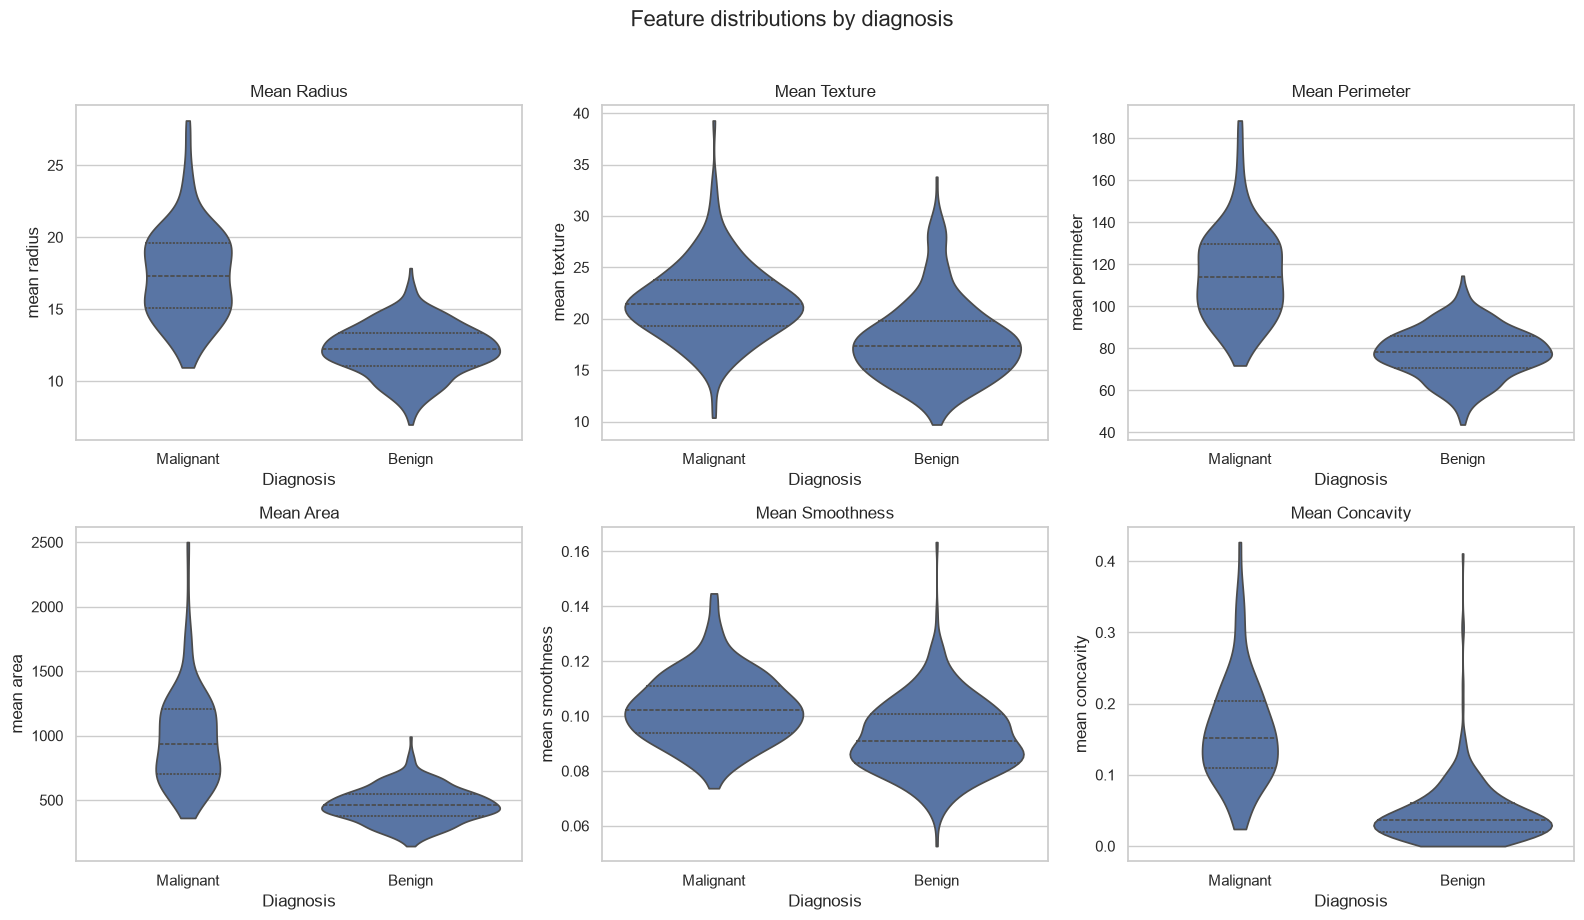

In [7]:
explore_cols = ["mean radius", "mean texture", "mean perimeter", "mean area",
                "mean smoothness", "mean concavity"]
plot_df = X[explore_cols].copy()
plot_df["Diagnosis"] = y.map({1: "Malignant", 0: "Benign"})
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, explore_cols):
    sns.violinplot(data=plot_df, x="Diagnosis", y=col, inner="quartile", cut=0, ax=ax)
    ax.set_title(col.replace("_", " ").title())
plt.suptitle("Feature distributions by diagnosis", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

### 2.2 Correlations

Highly correlated features may provide redundant information. Correlation does not imply causation; it is mainly useful for understanding the data and the limitations of directly interpreting model coefficients.

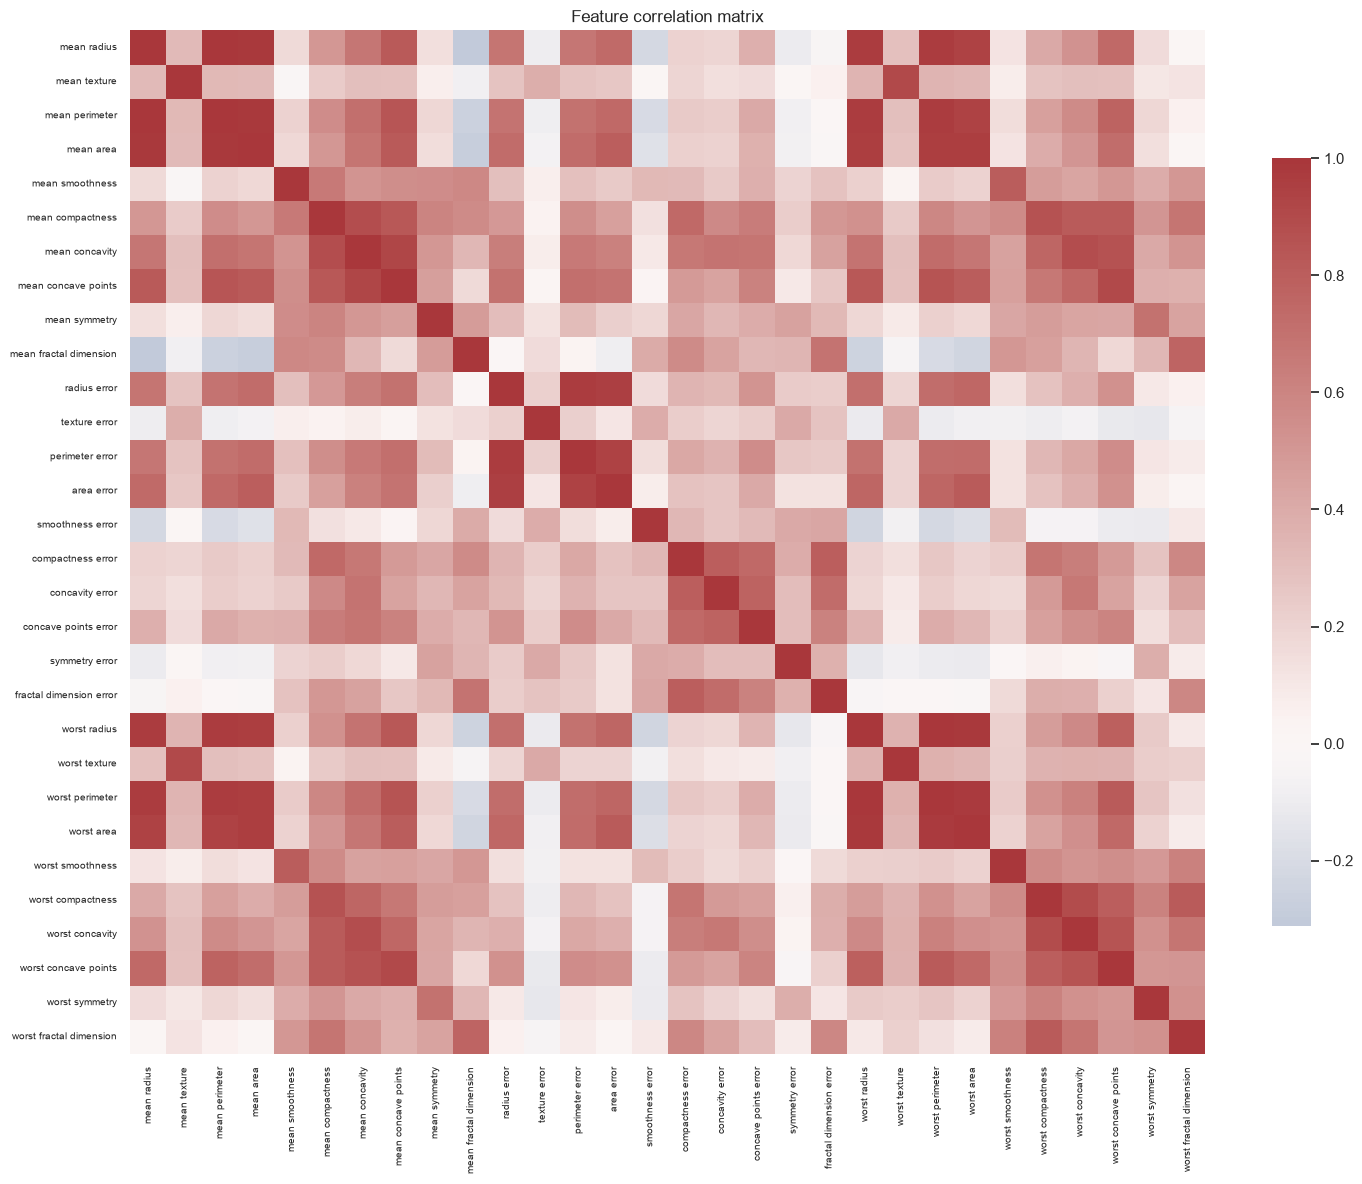

,Correlation with the malignant class
worst concave points,0.794
worst perimeter,0.783
mean concave points,0.777
worst radius,0.776
mean perimeter,0.743
worst area,0.734
mean radius,0.730
mean area,0.709
mean concavity,0.696
worst concavity,0.660


In [8]:
corr = X.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(corr, cmap="vlag", center=0, ax=ax, xticklabels=True, yticklabels=True,
            cbar_kws={"shrink": .75})
ax.set_title("Feature correlation matrix")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(fontsize=7)
plt.tight_layout()
plt.show()

corr_target = X.corrwith(y).sort_values()
display(pd.DataFrame({"Correlation with the malignant class": corr_target}).assign(
    Absolute_value=lambda d: d.iloc[:, 0].abs()
).sort_values("Absolute_value", ascending=False).drop(columns="Absolute_value").head(12))

## 3. Data Splitting — Preventing Data Leakage

The test set is held out now. All learned transformations (imputation and standardization) are placed inside pipelines and refitted within each cross-validation fold. The final test set will not be used for feature selection or hyperparameter tuning.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print("\nClass proportions (malignant class)")
display(pd.DataFrame({
    "Train": y_train.value_counts(normalize=True).sort_index(),
    "Test": y_test.value_counts(normalize=True).sort_index()
}, index=[0, 1]).rename(index={0: "Benign (0)", 1: "Malignant (1)"}))

Train: (455, 30) | Test: (114, 30)

Class proportions (malignant class)


,Train,Test
Benign (0),0.626,0.632
Malignant (1),0.374,0.368


## 4. Modeling and Evaluation Protocol

We compare a baseline with several model families. Models sensitive to feature scales use standardization. Median imputation is included for robustness, even though the audit indicates that there are no missing values.

**Priority metrics:**
- **Malignant recall:** proportion of malignant cases correctly detected.
- **Malignant precision:** among predictions labeled malignant, the proportion that are truly malignant.
- **Malignant F1-score:** balance between precision and recall.
- **ROC-AUC** and **Average Precision:** quality of the ranking of cases.
- **Balanced accuracy:** average recall across the two classes.

No single metric is sufficient for clinical use.

In [10]:
def pipeline_standardize(model):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", model)
    ])

models = {
    "Majority-class baseline": Pipeline([("imputer", SimpleImputer(strategy="median")),
                                      ("model", DummyClassifier(strategy="most_frequent"))]),
    "Logistic regression": pipeline_standardize(LogisticRegression(max_iter=5000, class_weight="balanced", random_state=SEED)),
    "SVM RBF": pipeline_standardize(SVC(C=1.0, kernel="rbf", probability=True, class_weight="balanced", random_state=SEED)),
    "K-nearest neighbors": pipeline_standardize(KNeighborsClassifier(n_neighbors=7)),
    "Gaussian Naive Bayes": pipeline_standardize(GaussianNB()),
    "Decision tree": Pipeline([("imputer", SimpleImputer(strategy="median")),
                                  ("model", DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=SEED))]),
    "Random forest": Pipeline([("imputer", SimpleImputer(strategy="median")),
                                 ("model", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                                  min_samples_leaf=2, random_state=SEED, n_jobs=-1))]),
    "Extra Trees": Pipeline([("imputer", SimpleImputer(strategy="median")),
                             ("model", ExtraTreesClassifier(n_estimators=300, class_weight="balanced",
                                                            min_samples_leaf=2, random_state=SEED, n_jobs=-1))]),
    "Gradient Boosting": Pipeline([("imputer", SimpleImputer(strategy="median")),
                                   ("model", GradientBoostingClassifier(random_state=SEED))]),
    "Hist Gradient Boosting": Pipeline([("imputer", SimpleImputer(strategy="median")),
                                        ("model", HistGradientBoostingClassifier(random_state=SEED))]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "malignant_recall": make_scorer(recall_score, pos_label=1, zero_division=0),
    "malignant_precision": make_scorer(precision_score, pos_label=1, zero_division=0),
    "malignant_f1": make_scorer(f1_score, pos_label=1, zero_division=0),
}

In [11]:
rows = []
for name, estimator in models.items():
    scores = cross_validate(estimator, X_train, y_train, cv=cv, scoring=scoring,
                            n_jobs=-1, return_train_score=False)
    row = {"Model": name}
    for metric in scoring:
        values = scores[f"test_{metric}"]
        row[f"{metric} mean"] = values.mean()
        row[f"{metric} standard deviation"] = values.std()
    rows.append(row)

comparison = pd.DataFrame(rows).sort_values("roc_auc mean", ascending=False).set_index("Model")
display(comparison.round(3))

,accuracy mean,accuracy standard deviation,balanced_accuracy mean,balanced_accuracy standard deviation,roc_auc mean,roc_auc standard deviation,average_precision mean,average_precision standard deviation,malignant_recall mean,malignant_recall standard deviation,malignant_precision mean,malignant_precision standard deviation,malignant_f1 mean,malignant_f1 standard deviation
Model,,,,,,,,,,,,,,
Logistic regression,0.971,0.018,0.969,0.020,0.995,0.005,0.994,0.005,0.959,0.030,0.965,0.029,0.962,0.024
SVM RBF,0.969,0.011,0.966,0.016,0.995,0.004,0.994,0.004,0.953,0.035,0.965,0.010,0.958,0.015
Hist Gradient Boosting,0.956,0.018,0.949,0.021,0.993,0.004,0.991,0.005,0.924,0.035,0.958,0.024,0.940,0.026
Extra Trees,0.969,0.016,0.965,0.019,0.992,0.005,0.990,0.006,0.947,0.034,0.970,0.019,0.958,0.022
Gradient Boosting,0.967,0.014,0.963,0.017,0.991,0.005,0.989,0.005,0.947,0.034,0.965,0.021,0.955,0.020
Random forest,0.963,0.015,0.962,0.016,0.990,0.006,0.988,0.006,0.959,0.030,0.943,0.029,0.950,0.020
Gaussian Naive Bayes,0.938,0.026,0.933,0.028,0.987,0.007,0.982,0.010,0.912,0.049,0.925,0.046,0.917,0.034
K-nearest neighbors,0.969,0.008,0.961,0.011,0.986,0.014,0.981,0.016,0.929,0.024,0.988,0.015,0.957,0.012
Decision tree,0.921,0.027,0.921,0.033,0.919,0.043,0.848,0.049,0.924,0.063,0.873,0.033,0.896,0.037


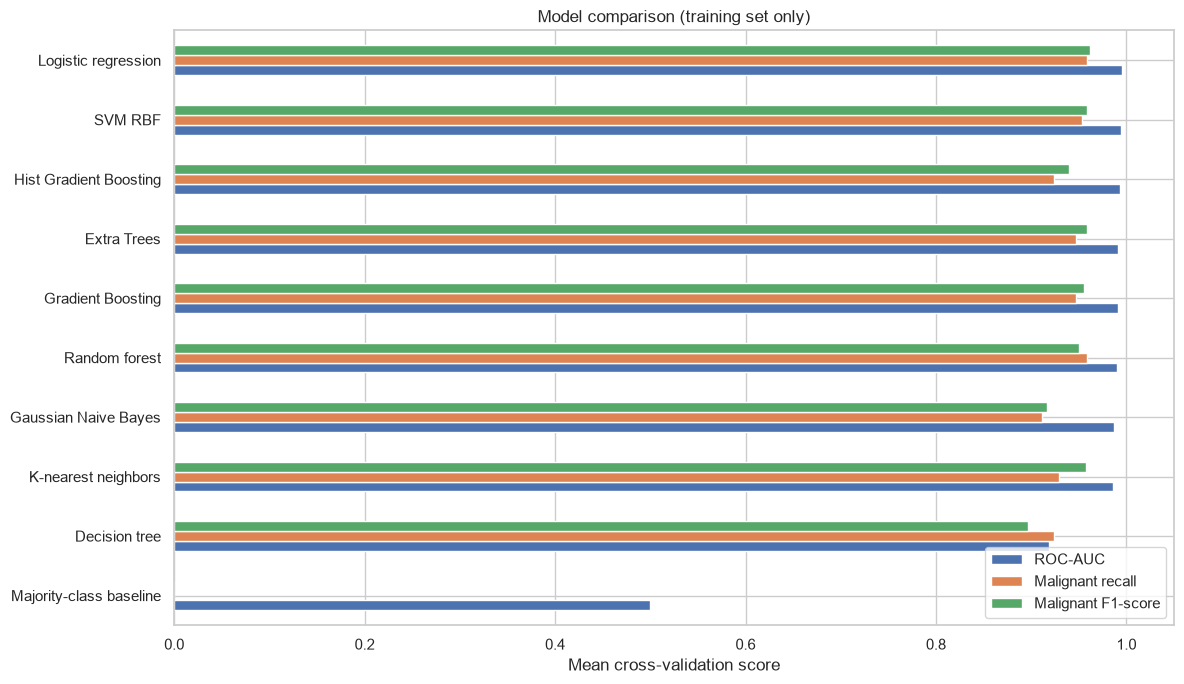

In [12]:
# Plot comparison of three important metrics
metrics_plot = ["roc_auc mean", "malignant_recall mean", "malignant_f1 mean"]
plot_compare = comparison[metrics_plot].sort_values("roc_auc mean")
ax = plot_compare.plot(kind="barh", figsize=(12, 7))
ax.set_xlim(0, 1.05)
ax.set_xlabel("Mean cross-validation score")
ax.set_ylabel("")
ax.set_title("Model comparison (training set only)")
ax.legend(["ROC-AUC", "Malignant recall", "Malignant F1-score"], loc="lower right")
plt.tight_layout()
plt.show()

## 5. Model Tuning

We tune logistic regression using a hyperparameter grid and stratified cross-validation. The selection criterion is malignant-class recall, while also monitoring AUC. This choice illustrates a priority of reducing false negatives; it is not a universal clinical recommendation.

In [13]:
pipeline_lr = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=8000, class_weight="balanced", random_state=SEED))
])
param_grid = {
    "model__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "model__solver": ["liblinear", "lbfgs"],
}
search = GridSearchCV(
    pipeline_lr, param_grid, scoring="recall", cv=cv, n_jobs=-1,
    refit=True, return_train_score=True
)
search.fit(X_train, y_train)
print("Best parameters:", search.best_params_)
print(f"Best cross-validation recall: {search.best_score_:.3f}")

Best parameters: {'model__C': 0.1, 'model__solver': 'liblinear'}
Best cross-validation recall: 0.959


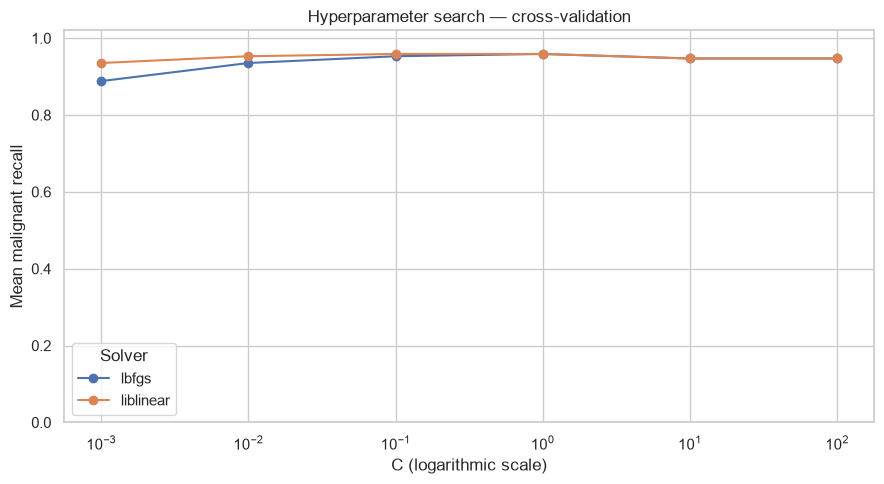

In [14]:
grid_results = pd.DataFrame(search.cv_results_)
grid_results["C"] = grid_results["param_model__C"].astype(float)
fig, ax = plt.subplots(figsize=(9, 5))
for solver, group in grid_results.groupby("param_model__solver"):
    means = group.groupby("C")["mean_test_score"].mean().sort_index()
    ax.plot(means.index, means.values, marker="o", label=solver)
ax.set_xscale("log")
ax.set_ylim(0, 1.02)
ax.set_xlabel("C (logarithmic scale)")
ax.set_ylabel("Mean malignant recall")
ax.set_title("Hyperparameter search — cross-validation")
ax.legend(title="Solver")
plt.tight_layout()
plt.show()

## 6. Final Evaluation on the Test Set

This section evaluates the selected model on the held-out data. The target is defined as `1 = malignant`, so the probability used corresponds to class `1`. Results should be interpreted cautiously given the modest dataset size.

In [15]:
best_model = search.best_estimator_
y_pred = best_model.predict(X_test)
y_proba_malignant = best_model.predict_proba(X_test)[:, list(best_model.classes_).index(1)]

final_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
    "Malignant precision": precision_score(y_test, y_pred, zero_division=0),
    "Malignant recall": recall_score(y_test, y_pred, zero_division=0),
    "Malignant F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC (malignant positive)": roc_auc_score(y_test, y_proba_malignant),
    "Average Precision": average_precision_score(y_test, y_proba_malignant),
}
display(pd.DataFrame.from_dict(final_metrics, orient="index", columns=["Score"]))
print("\nClassification report (1 = malignant):")
print(classification_report(y_test, y_pred, target_names=["Benign", "Malignant"], zero_division=0))

,Score
Accuracy,0.991
Balanced accuracy,0.988
Malignant precision,1.000
Malignant recall,0.976
Malignant F1-score,0.988
ROC-AUC (malignant positive),0.998
Average Precision,0.997



Classification report (1 = malignant):
              precision    recall  f1-score   support

      Benign       0.99      1.00      0.99        72
   Malignant       1.00      0.98      0.99        42

    accuracy                           0.99       114
   macro avg       0.99      0.99      0.99       114
weighted avg       0.99      0.99      0.99       114



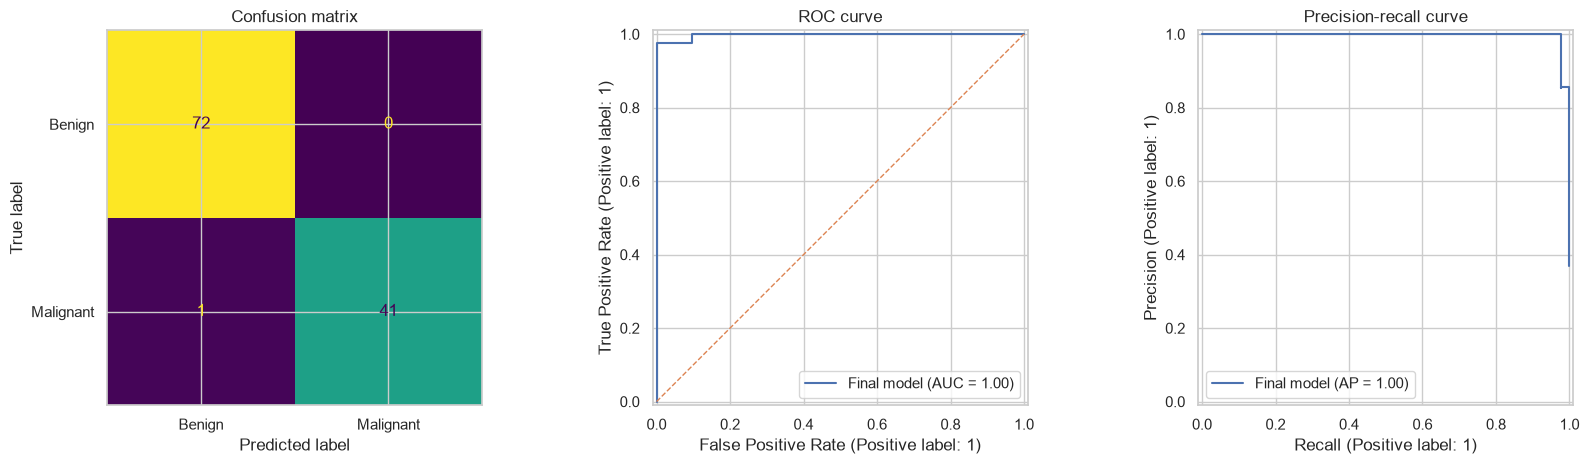

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=["Benign", "Malignant"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix")

RocCurveDisplay.from_predictions(y_test, y_proba_malignant, ax=axes[1], name="Final model")
axes[1].plot([0, 1], [0, 1], linestyle="--", linewidth=1)
axes[1].set_title("ROC curve")

PrecisionRecallDisplay.from_predictions(y_test, y_proba_malignant, ax=axes[2], name="Final model")
axes[2].set_title("Precision-recall curve")
plt.tight_layout()
plt.show()

### 6.1 Error Analysis

False negatives are malignant cases predicted as benign; false positives are benign cases predicted as malignant. These two types of errors have different consequences. The model must not be used to make medical decisions.

In [17]:
errors = X_test.copy()
errors["Actual"] = y_test.map({0: "Benign", 1: "Malignant"})
errors["Predicted"] = pd.Series(y_pred, index=y_test.index).map({0: "Benign", 1: "Malignant"})
errors["Malignant probability"] = y_proba_malignant
errors["Error type"] = np.select(
    [(y_test.values == 1) & (y_pred == 0), (y_test.values == 0) & (y_pred == 1)],
    ["False negative", "False positive"], default="Correct"
)
display(errors.loc[errors["Error type"] != "Correct",
                   ["Actual", "Predicted", "Malignant probability", "Error type"]].sort_values("Malignant probability"))

,Actual,Predicted,Malignant probability,Error type
73,Malignant,Benign,0.224,False negative


## 7. Interpretability: Permutation Importance

Permutation importance measures the decrease in performance when a feature is shuffled. It is calculated on the test set here as a post-evaluation analysis; it must not be used to modify the model and then report the same test scores again. Correlated features may share or mask one another's importance.

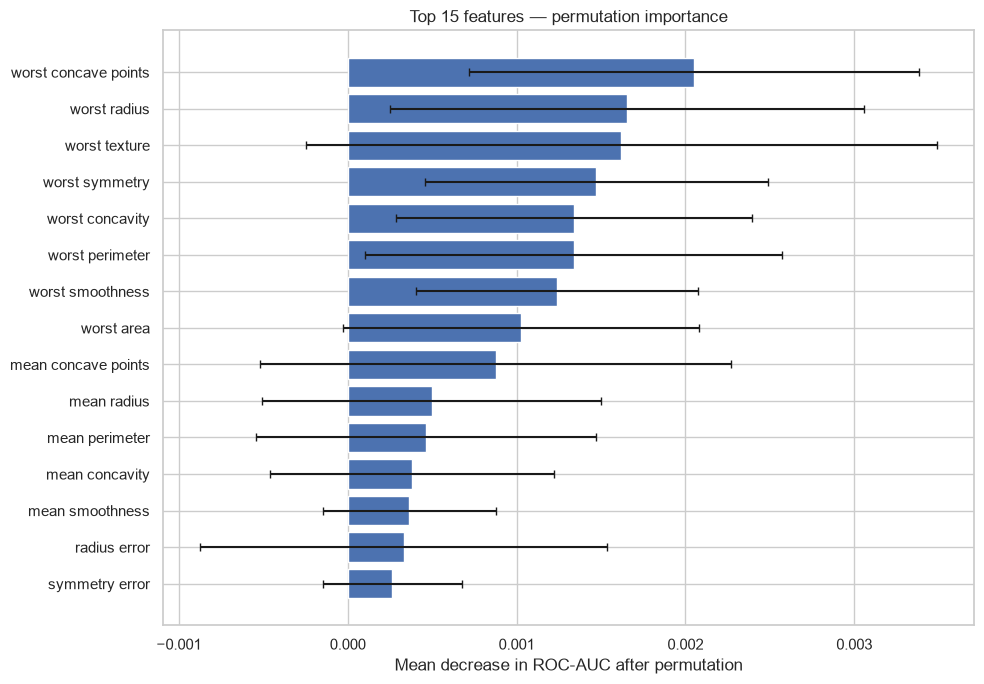

,Feature,Mean importance,Standard deviation
27,worst concave points,2.050e-03,1.333e-03
20,worst radius,1.653e-03,1.403e-03
21,worst texture,1.620e-03,1.870e-03
28,worst symmetry,1.472e-03,1.016e-03
26,worst concavity,1.339e-03,1.053e-03
22,worst perimeter,1.339e-03,1.235e-03
24,worst smoothness,1.240e-03,8.358e-04
23,worst area,1.025e-03,1.056e-03
7,mean concave points,8.763e-04,1.396e-03
0,mean radius,4.960e-04,1.006e-03


In [18]:
perm = permutation_importance(
    best_model, X_test, y_test, scoring="roc_auc",
    n_repeats=20, random_state=SEED, n_jobs=-1
)
importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean importance": perm.importances_mean,
    "Standard deviation": perm.importances_std
}).sort_values("Mean importance", ascending=False).head(15)

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(importance["Feature"][::-1], importance["Mean importance"][::-1],
        xerr=importance["Standard deviation"][::-1], capsize=3)
ax.set_xlabel("Mean decrease in ROC-AUC after permutation")
ax.set_title("Top 15 features — permutation importance")
plt.tight_layout()
plt.show()
display(importance)

## 8. Unsupervised Exploration (Additional Analysis)

Clustering is exploratory and does not replace the supervised classifier. Features are standardized using the training set only. The number of clusters is set to 2 for this experiment, which is a strong assumption; diagnostic labels are used only after clustering to calculate external evaluation scores.

In [19]:
X_train_scaled = StandardScaler().fit_transform(X_train)
kmeans = KMeans(n_clusters=2, n_init=20, random_state=SEED)
clusters = kmeans.fit_predict(X_train_scaled)
cluster_scores = pd.DataFrame([{
    "Silhouette": silhouette_score(X_train_scaled, clusters),
    "ARI vs. diagnosis": adjusted_rand_score(y_train, clusters),
    "NMI vs. diagnosis": normalized_mutual_info_score(y_train, clusters)
}], index=["K-means"])
display(cluster_scores.round(3))

D:\Program Files\anaconda\envs\xray\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


,Silhouette,ARI vs. diagnosis,NMI vs. diagnosis
K-means,0.343,0.662,0.54


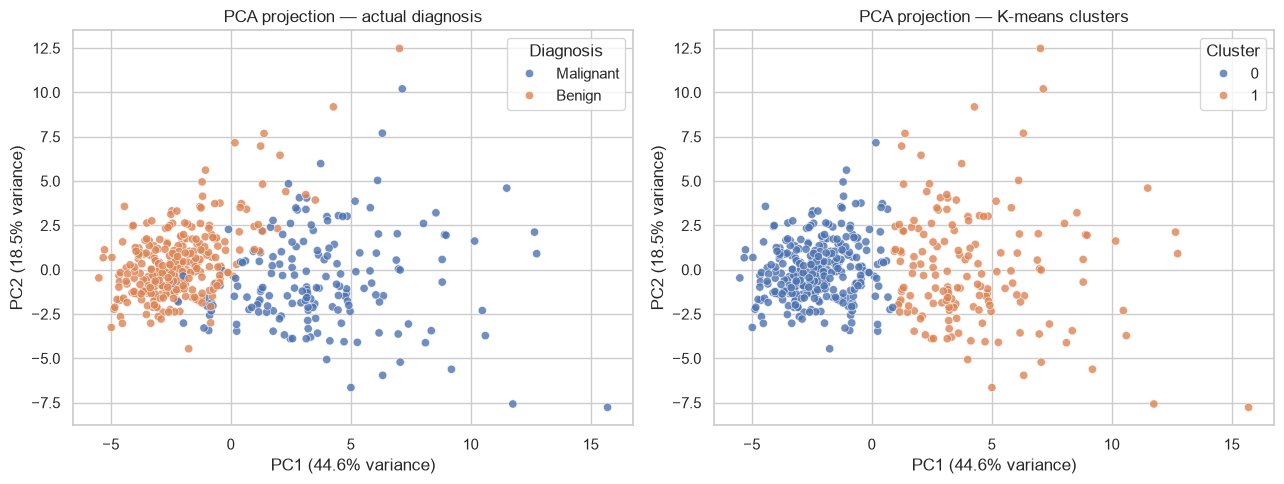

In [20]:
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_train_scaled)
pca_df = pd.DataFrame({"PC1": X_pca[:, 0], "PC2": X_pca[:, 1],
                       "Diagnosis": y_train.map({0: "Benign", 1: "Malignant"}).values,
                       "Cluster": clusters.astype(str)})
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Diagnosis", alpha=.8, ax=axes[0])
axes[0].set_title("PCA projection — actual diagnosis")
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Cluster", alpha=.8, ax=axes[1])
axes[1].set_title("PCA projection — K-means clusters")
for ax in axes:
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.tight_layout()
plt.show()

## 9. Conclusions and Limitations

### What this project demonstrates
- A reproducible workflow, from data quality checks to evaluation.
- Comparison of multiple models using stratified cross-validation.
- Hyperparameter selection restricted to the training set.
- Final evaluation using metrics suited to the malignant class, curves, and error analysis.
- An initial interpretability analysis and an additional unsupervised exploration.

### Limitations
1. **Small and relatively old dataset:** 569 observations; performance may vary considerably on other data.
2. **No external validation:** no testing on an independent institution or population.
3. **Structured data only:** this project does not directly process MRI or mammography images.
4. **Decision threshold:** the default threshold of 0.5 may not be optimal; the choice depends on the context and must be validated.
5. **Bias and fairness:** the representativeness of subgroups is not studied here.
6. **Interpretability:** feature importance does not imply causality or provide clinical evidence.
7. **Use:** for learning purposes only, never for diagnosis or medical advice.

### Possible improvements for a research version
- External validation on an independent dataset, with the protocol specified in advance.
- Calibration analysis and bootstrap confidence intervals.
- Threshold analysis based on an objective defined with domain professionals.
- Comparison with regularized models and feature selection integrated into cross-validation.
- Reproducibility report covering library versions, protocol, random seeds, and limitations.

In [22]:

summary_df = pd.DataFrame({
    "Metric": list(final_metrics.keys()),
    "Test value": list(final_metrics.values())
})
display(summary_df.style.format({"Test value": "{:.3f}"}).hide(axis="index"))
print("Final model:", search.best_estimator_.named_steps["model"])
print("Selected parameters:", search.best_params_)

Metric,Test value
Accuracy,0.991
Balanced accuracy,0.988
Malignant precision,1.000
Malignant recall,0.976
Malignant F1-score,0.988
ROC-AUC (malignant positive),0.998
Average Precision,0.997


Final model: LogisticRegression(C=0.1, class_weight='balanced', max_iter=8000,
                   random_state=42, solver='liblinear')
Selected parameters: {'model__C': 0.1, 'model__solver': 'liblinear'}
